In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv('/home/walml/repos/gz-panoptes-reduction/notebooks/results_gz-cosmos-2025-05-22.csv')
df

,subject_id,probability_at_least_20pc_featured,smooth-or-featured-cd_smooth_prediction,smooth-or-featured-cd_featured-or-disk_prediction,smooth-or-featured-cd_problem_prediction
0,108636953,1.0000,45.924999,78.351997,6.993000
1,108636980,0.0005,71.477997,11.388000,38.563999
2,108636987,0.0000,4.094000,2.440000,71.920998
3,108636995,0.0000,81.545998,11.769000,49.779999
4,108636998,0.0000,52.205002,6.987000,71.681999
...,...,...,...,...,...
309316,108690365,0.0000,52.884998,5.328000,70.236000
309317,108693156,0.8385,41.293999,31.653999,61.055000
309318,108693736,0.0006,69.637001,13.642000,54.032001
309319,108694373,0.0008,37.974998,9.434000,57.654999


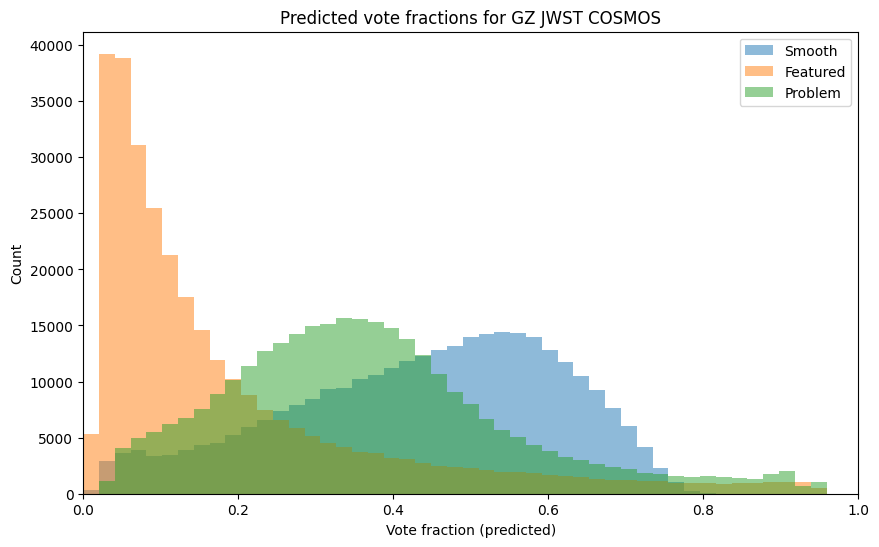

In [3]:
pred_cols = [col for col in df.columns if 'pred' in col]
df['pred_sum'] = df[pred_cols].sum(axis=1)

for col in pred_cols:
    df[col.replace('_prediction', '_fraction')] = df[col] / df['pred_sum']

fig, ax = plt.subplots(figsize=(10, 6))

bins = np.linspace(0, 1, 50)
ax.hist(df['smooth-or-featured-cd_smooth_fraction'], bins=bins, alpha=0.5, label='Smooth')
ax.hist(df['smooth-or-featured-cd_featured-or-disk_fraction'], bins=bins, alpha=0.5, label='Featured')
ax.hist(df['smooth-or-featured-cd_problem_fraction'], bins=bins, alpha=0.5, label='Problem')

ax.set_xlim([0, 1])
ax.set_xlabel('Vote fraction (predicted)')
ax.set_ylabel('Count')

ax.set_title('Predicted vote fractions for GZ JWST COSMOS')

ax.legend()

Text(0.5, 1.0, 'Vote fractions for GZ JWST COSMOS')

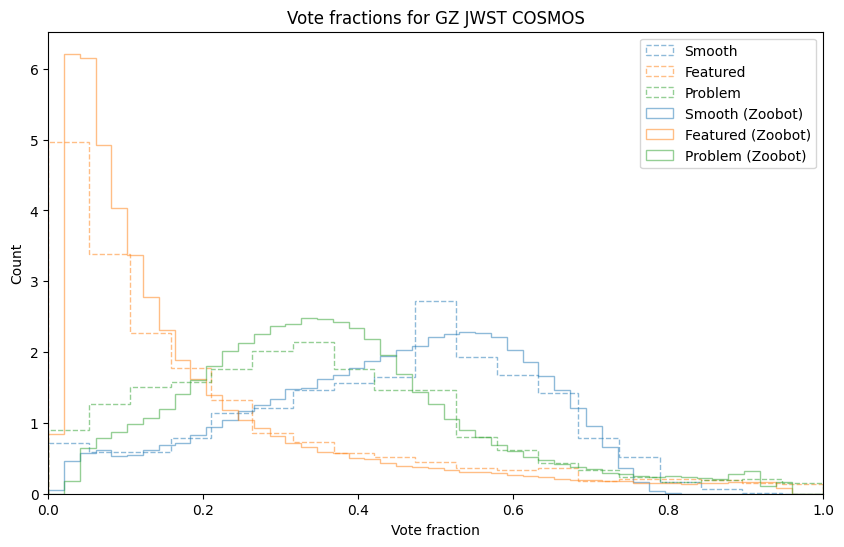

In [4]:
vol = pd.read_csv('/home/walml/repos/gz-panoptes-reduction/data/jwst_cosmos/jwst-cosmos_reduced_votes.csv')

fig, ax = plt.subplots(figsize=(10, 6))

# get matplotlib color cycle

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

bins = np.linspace(0, 1, 20)
ax.hist(vol['smooth-or-featured_smooth_fraction'], bins=bins, alpha=0.5, label='Smooth', histtype='step', density=True, color=colors[0], linestyle='--')
ax.hist(vol['smooth-or-featured_featured-or-disk_fraction'], bins=bins, alpha=0.5, label='Featured', histtype='step', density=True, color=colors[1], linestyle='--')
ax.hist(vol['smooth-or-featured_star-artifact-zoom_fraction'], bins=bins, alpha=0.5, label='Problem', histtype='step', density=True, color=colors[2], linestyle='--')

bins = np.linspace(0, 1, 50)
ax.hist(df['smooth-or-featured-cd_smooth_fraction'], bins=bins, alpha=0.5, label='Smooth (Zoobot)', histtype='step', density=True, color=colors[0])
ax.hist(df['smooth-or-featured-cd_featured-or-disk_fraction'], bins=bins, alpha=0.5, label='Featured (Zoobot)', histtype='step', density=True, color=colors[1])
ax.hist(df['smooth-or-featured-cd_problem_fraction'], bins=bins, alpha=0.5, label='Problem (Zoobot)', histtype='step', density=True, color=colors[2])

ax.legend()

ax.set_xlabel('Vote fraction')
ax.set_ylabel('Count')

ax.set_xlim([0, 1])

ax.set_title('Vote fractions for GZ JWST COSMOS')

In [5]:
high_problem = vol['smooth-or-featured_star-artifact-zoom_fraction'] > 0.5


vol['url_first_frame']


0        https://panoptes-uploads.zooniverse.org/subjec...
1        https://panoptes-uploads.zooniverse.org/subjec...
2        https://panoptes-uploads.zooniverse.org/subjec...
3        https://panoptes-uploads.zooniverse.org/subjec...
4        https://panoptes-uploads.zooniverse.org/subjec...
                               ...                        
10804    https://panoptes-uploads.zooniverse.org/subjec...
10805    https://panoptes-uploads.zooniverse.org/subjec...
10806    https://panoptes-uploads.zooniverse.org/subjec...
10807    https://panoptes-uploads.zooniverse.org/subjec...
10808    https://panoptes-uploads.zooniverse.org/subjec...
Name: url_first_frame, Length: 10809, dtype: object

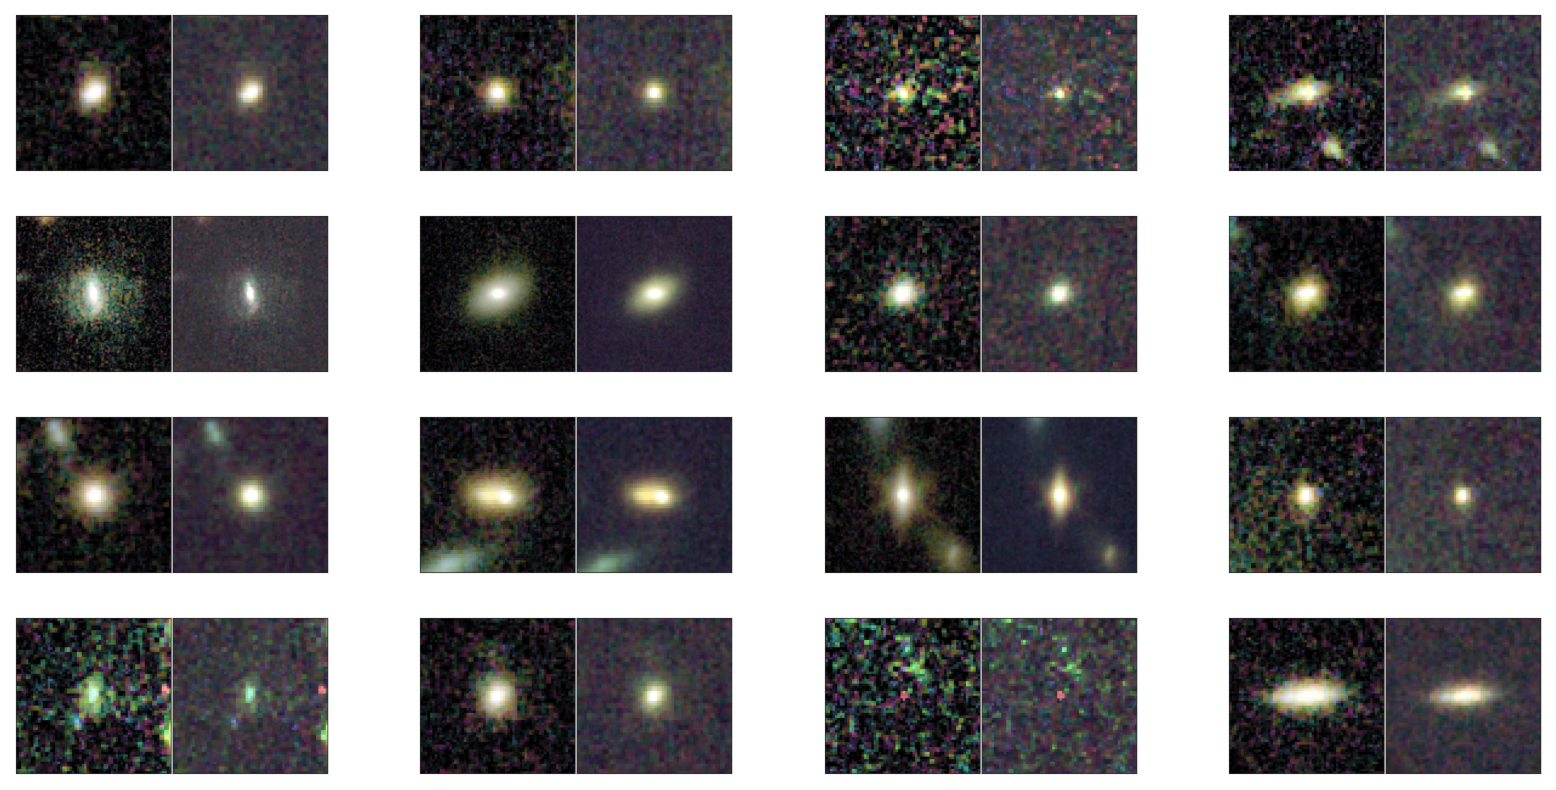

In [14]:
# create grid of 4x4 subplots

def show_examples(df):

    fig, axs = plt.subplots(4, 4, figsize=(20, 10))
    axs = axs.flatten()

    import requests
    from PIL import Image
    from io import BytesIO

    for i, ax in enumerate(axs):
        if i >= len(df):
            break
        url = df['url_first_frame'].iloc[i]
        response = requests.get(url)
        img = Image.open(BytesIO(response.content))
        ax.imshow(img)
        # ax.set_title(f'ID: {df["zooniverse_id"].iloc[i]}')
        ax.axis('off')

    return fig, axs



fig, axs = show_examples(vol.sample(16))

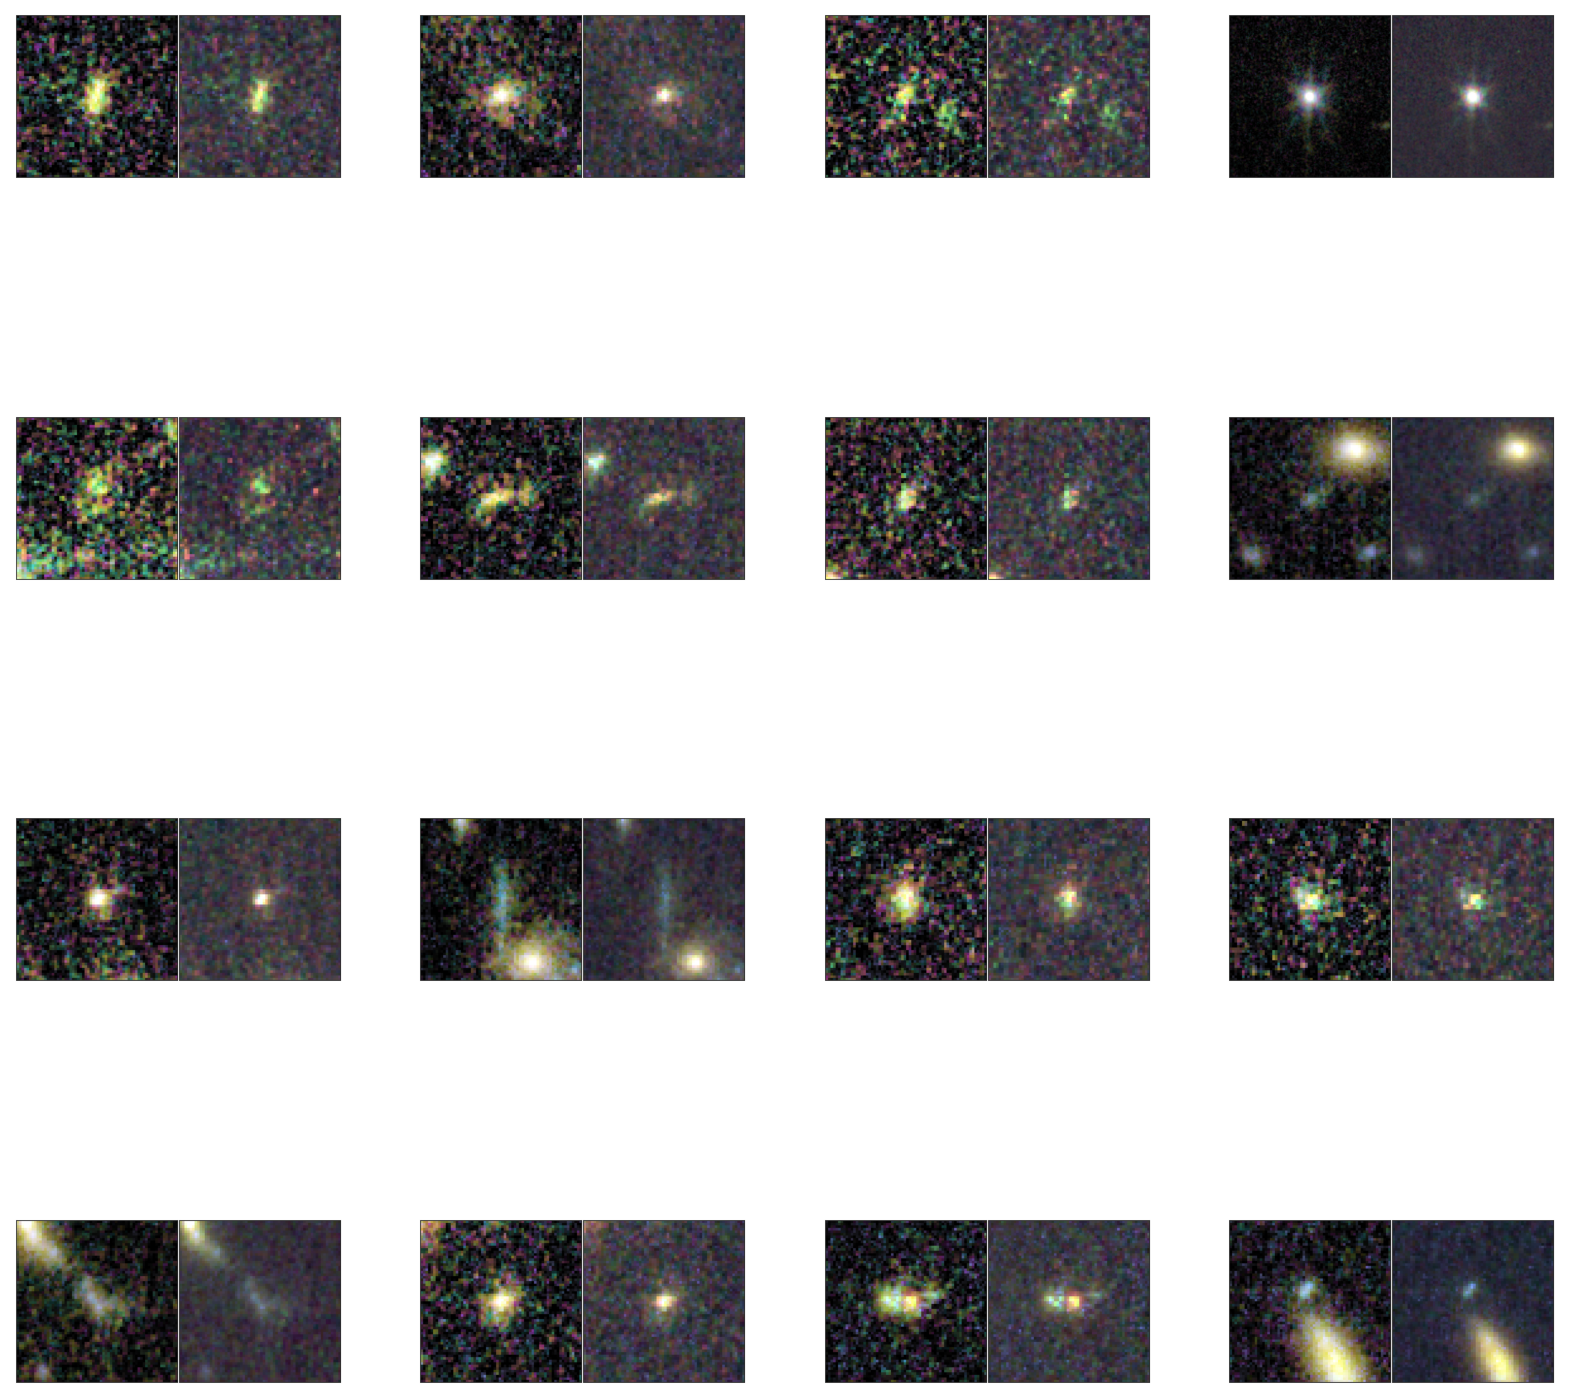

In [7]:

fig, axs = show_examples(vol[high_problem].sample(16))

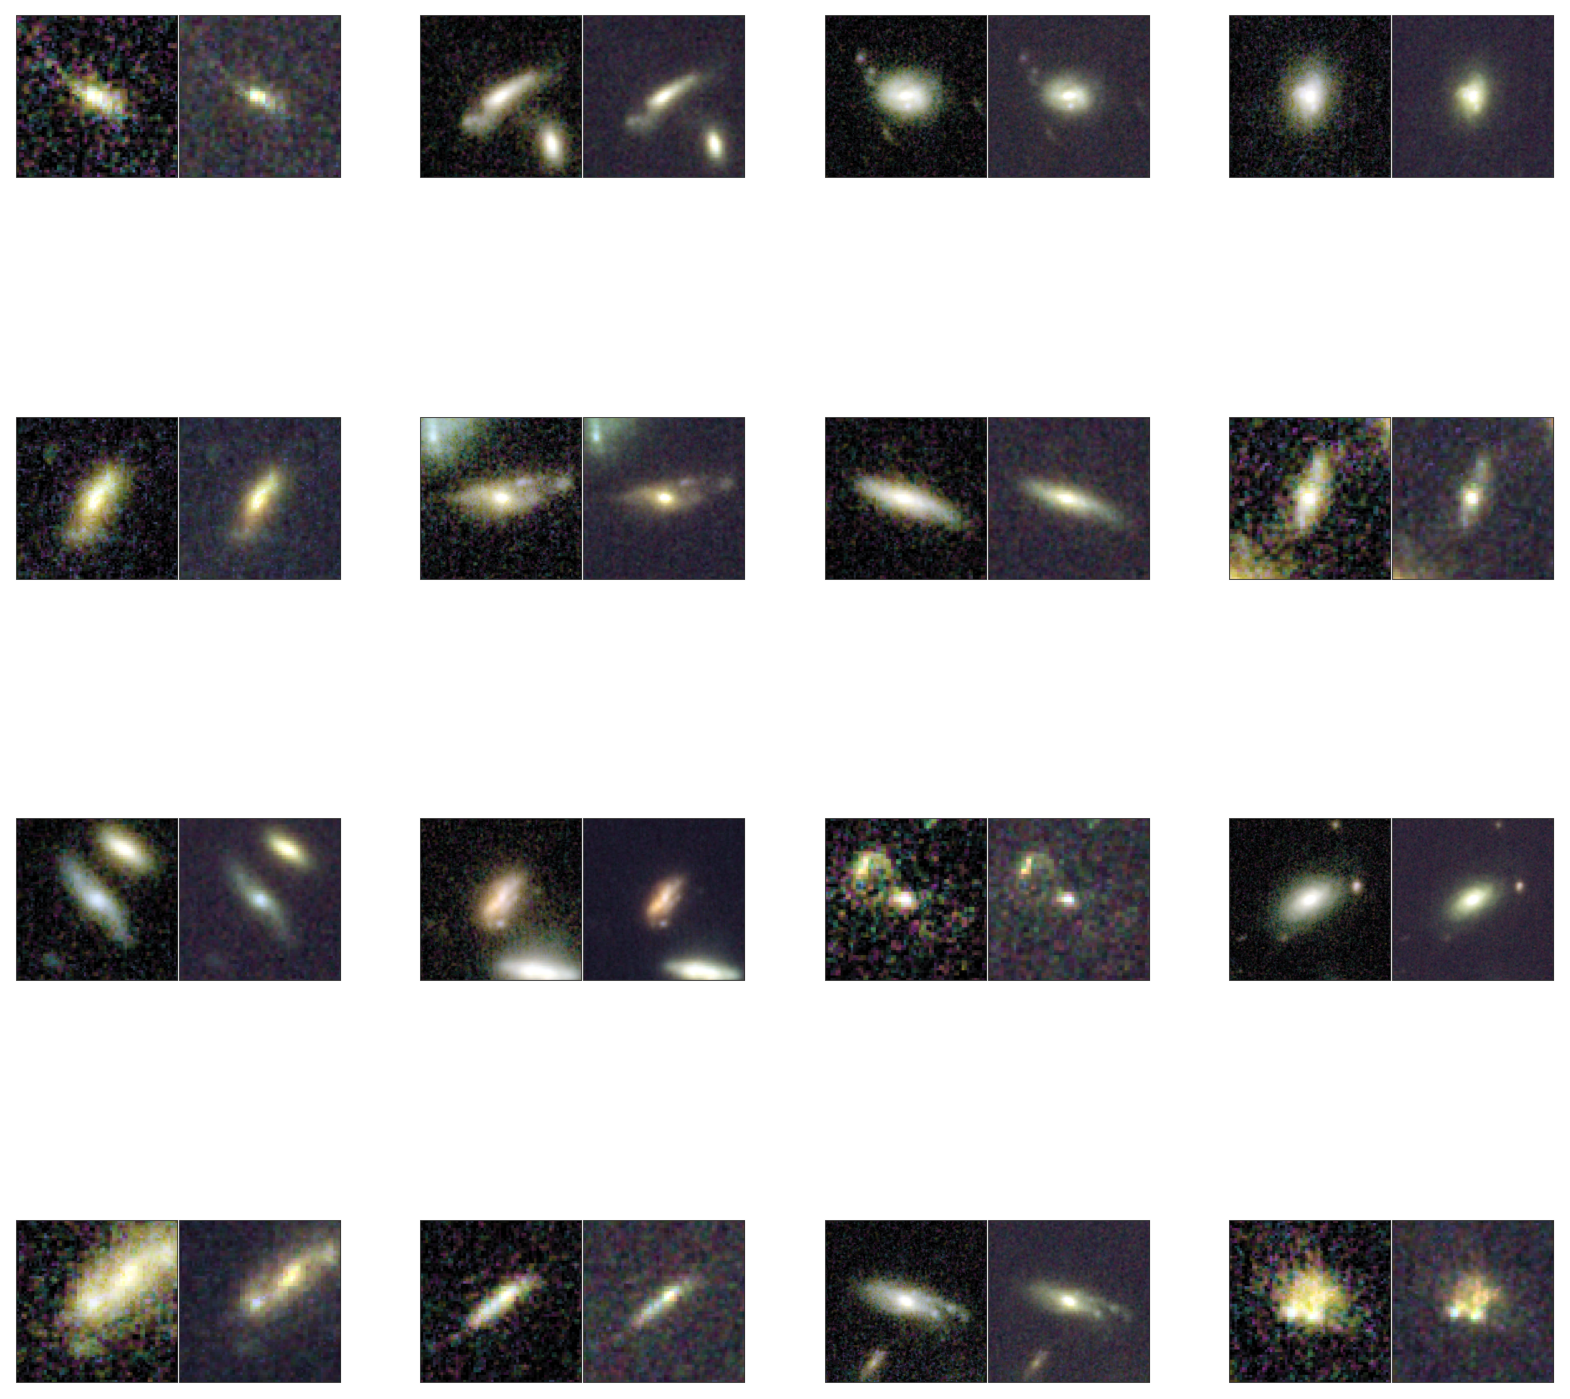

In [8]:
featured_above_0p2 = vol['smooth-or-featured_featured-or-disk_fraction'] > 0.2
fig, axs = show_examples(vol[featured_above_0p2].sample(16))


In [9]:
vol['id_str']

0        140468011
1        140468011
2        140468011
3        140468173
4        140468173
           ...    
10804    140565007
10805    140565008
10806    140565008
10807    140565009
10808    140565009
Name: id_str, Length: 10809, dtype: int64

In [12]:
# metadata = pd.read_csv(
#     '/home/walml/repos/gz-panoptes-reduction/notebooks/colour_cutout_master_catalogue_w_metadata.csv', 
#     # usecols=['id_str', '!RA', '!Dec', 'AREA', '!radius', 'AXRATIO']),
#     nrows=1000
# )
# metadata.iloc[0]

In [11]:
# metadata